# 04 — Feature Engineering & Baseline Model (DSC LOGIKA UI 2026, Credit Risk)

This notebook takes `base_aggregated.parquet` from notebook 03 and does four things:

1. Fix the **validation strategy** (answers Business Question 3) before any modeling.
2. Add **business-driven & cross-table features** (answers Business Question 1 & 2, grounded in EDA and 03 aggregation).
3. **Select features** (KS filter + correlation pruning) using training data only.
4. Train a **baseline model**, report all metrics, and write a first `submission_baseline.csv`.

Rules for this notebook:
- Every feature uses only information from `base_aggregated`, which was already cut off at each application's `decision_datetime` in notebook 03.
- Anything that uses `target` (KS filter, importance) is computed on the **training part of each fold only**, never on validation rows.
- Same seed, same folds and same `ks_score()` for every experiment.

#### Cell 4.1 — Setup, Seed, Load `base_aggregated`

**What to do:** Set the seed, load the parquet saved by notebook 03 and split it into train and test.

**Why:** Reproducibility and a single entry point for all later cells.

**What to look for:** `train_df` is (70000, 278) and `test_df` is (30000, 278) including an empty `target` column. No duplicate `application_id`.

In [1]:
import os
import random
import platform
import importlib.util
import lightgbm as lgb

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp
from sklearn.metrics import roc_auc_score, log_loss, average_precision_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

cwd = os.path.abspath(os.getcwd())
ROOT = cwd if os.path.exists(os.path.join(cwd, "dataset")) else os.path.abspath(os.path.join(cwd, ".."))
DATA_DIR = os.path.join(ROOT, "dataset")
OUT_DIR = os.path.join(ROOT, "output")
os.makedirs(OUT_DIR, exist_ok=True)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.4f}".format)

parquet_path = os.path.join(OUT_DIR, "base_aggregated.parquet")
pickle_path = os.path.join(OUT_DIR, "base_aggregated.pkl")
base = pd.read_parquet(parquet_path) if os.path.exists(parquet_path) else pd.read_pickle(pickle_path)

USE_LGBM = importlib.util.find_spec("lightgbm") is not None
print("SEED =", SEED, "| python", platform.python_version(), "| pandas", pd.__version__)
print("Model backend:", "LightGBM" if USE_LGBM else "sklearn HistGradientBoosting (lightgbm not installed)")
print("base shape:", base.shape)

assert base["application_id"].is_unique
assert int(base["is_train"].sum()) == 70_000
print("train / test rows:", int(base["is_train"].sum()), "/", int((base["is_train"] == 0).sum()))
print("target rate (train): %.4f" % base.loc[base["is_train"] == 1, "target"].mean())

SEED = 42 | python 3.11.16 | pandas 3.0.6
Model backend: LightGBM
base shape: (100000, 491)
train / test rows: 70000 / 30000
target rate (train): 0.1358


#### Cell 4.2 — Validation Strategy (Business Question 3)

**What to do:** Sort train by `application_datetime` and build three **expanding-window** folds. The last fold is the main holdout: train on the earliest 80%, validate on the latest 20%.

**Why:** Train and test covers 2024-12-27 to 2025-12-28. A random split would let the model see future patterns and overstate KS. A time split mimics what really happens at deployment. Because `customer_id` is unique in all 100,000 rows, there is no same-customer overlap to handle.

**What to look for:** Date ranges that never overlap between train and validation inside each fold, and similar default rates across folds. A clear drift in default rate means the later fold is harder and the KS numbers will drop.

In [2]:
from sklearn.model_selection import StratifiedKFold

train_df = base[base["is_train"] == 1].reset_index(drop=True)
test_df = base[base["is_train"] == 0].reset_index(drop=True)

N_SPLITS = 5
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
folds = list(skf.split(train_df, train_df["target"]))
MAIN_FOLD = 0

rows = []
for i, (tr, va) in enumerate(folds):
    rows.append({
        "fold": i + 1,
        "train_rows": len(tr),
        "valid_rows": len(va),
        "train_default_rate": train_df.loc[tr, "target"].mean(),
        "valid_default_rate": train_df.loc[va, "target"].mean(),
    })
fold_table = pd.DataFrame(rows)
print(fold_table.to_string(index=False))

 fold  train_rows  valid_rows  train_default_rate  valid_default_rate
    1       56000       14000              0.1358              0.1358
    2       56000       14000              0.1358              0.1358
    3       56000       14000              0.1358              0.1358
    4       56000       14000              0.1358              0.1359
    5       56000       14000              0.1358              0.1359


#### Cell 4.3 — Metric Helper

**What to do:** One function that returns KS (main metric), ROC AUC, Gini, Log Loss and PR AUC.

**Why:** Business Question 3 and the pipeline standard require the same evaluation for every experiment.

**What to look for:** Gini should equal `2 * AUC - 1` exactly. KS should always be at most 1.

In [3]:
def ks_score(y_true, y_score):
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score)
    return ks_2samp(y_score[y_true == 1], y_score[y_true == 0]).statistic


def evaluate(y_true, y_score):
    auc = roc_auc_score(y_true, y_score)
    return {
        "KS": ks_score(y_true, y_score),
        "AUC": auc,
        "Gini": 2 * auc - 1,
        "LogLoss": log_loss(y_true, np.clip(y_score, 1e-6, 1 - 1e-6)),
        "PR_AUC": average_precision_score(y_true, y_score),
    }

_demo = evaluate(np.array([0, 0, 1, 1, 0, 1]), np.array([0.1, 0.3, 0.8, 0.6, 0.2, 0.4]))
print({k: round(v, 4) for k, v in _demo.items()})
assert abs(_demo["Gini"] - (2 * _demo["AUC"] - 1)) < 1e-12

{'KS': np.float64(1.0), 'AUC': 1.0, 'Gini': 1.0, 'LogLoss': 0.3892, 'PR_AUC': 1.0}


#### Cell 4.4 — Business-Driven & Cross-Table Feature Engineering (Business Questions 1 & 2)

**What to do:** Build domain-grounded features across six credit-risk pillars using only `base_aggregated` columns (all strictly cut off before `decision_datetime`), label-encode categorical columns, and clean `±inf` values:
1. **Affordability & Debt-Service Burden (Spine × Profile):** DTI (`installment_to_income`), LTI (`loan_to_annual_income`), dependent-adjusted income and installment burden, interest cost ratios, and employment stability (`tenure_to_age`).
2. **Pricing & Loan Escalation (Spine × Previous Applications):** Interest rate markup vs. past loans (`interest_rate_diff_vs_prev`, `interest_rate_ratio_vs_prev`), loan size escalation (`loan_amount_to_prev_requested_mean`), and installment jump (`installment_to_prev_installment`).
3. **Verified Cashflow & Debt Capacity (Account & Bureau × Spine):** Bank-verified income vs. declared income (`verified_to_declared_income`), installment coverage by recent 3-month net cashflow (`installment_to_net_cashflow_3m`) and minimum balance (`installment_to_min_balance_3m`), plus total external + new debt leverage (`total_debt_to_annual_income`, `bur_outstanding_to_income`).
4. **Bureau Trajectory & Score Disagreement (Current vs. Previous Bureau):** Score migration (`bur_score_delta_curr_vs_prev`), inter-bureau dispersion (`bur_score_spread_curr`), utilization shift (`bur_util_delta_curr_vs_prev`), and debt growth (`bur_outstanding_ratio_curr_vs_prev`).
5. **Repayment Deterioration & Compounding Stress (Repayment × Bureau & Spine):** Recent DPD acceleration (`rep_dpd_trend_last3_vs_all`, `rep_dpd30_rate_ratio_last6_vs_all`) and multiplicative stress interactions (`util_x_rep_dpd30_rate`, `util_x_recent_late`, `rep_dpd_x_interest_rate`).
6. **E-Commerce Spending Surge & Lifestyle Inflation (E-Commerce × Spine & Account):** 90-day spending concentration (`ecom_spend_90d_share`), order size acceleration (`ecom_order_accel_90d_vs_older`), recent monthly spend to income (`ecom_monthly_spend_90d_to_income`), share of 3m bank outflows (`ecom_spend_90d_to_outflows_3m`), and joint spending-outflow surge (`ecom_spend_90d_x_outflow_surge`).

**Why:** Notebook 01 & 02 highlight that affordability, historical delinquency, external credit utilization, and pre-application spending surges jointly separate defaulters from good borrowers. Ratios and deltas are also more stationary across time than raw IDR amounts.

**What to look for:** Zero `inf` values, strong univariate KS on the new cross-table features, and preserved row counts (70,000 train / 30,000 test).

In [4]:
def safe_div(a, b):
    if isinstance(b, pd.Series):
        denom = b.replace(0, np.nan)
    else:
        denom = np.where(b == 0, np.nan, b)
    out = a / denom
    return out.replace([np.inf, -np.inf], np.nan)


def add_features(df, tr_folds, n_train):
    df = df.copy()
    income = df["declared_monthly_income"]
    annual_income = income * 12.0

    eng = {}

    eng["installment_to_income"] = safe_div(df["proposed_monthly_installment"], income)
    eng["loan_to_annual_income"] = safe_div(df["loan_amount"], annual_income)
    eng["income_per_dependent"] = safe_div(income, df["dependents"] + 1.0)
    eng["installment_per_dependent_income"] = safe_div(df["proposed_monthly_installment"], eng["income_per_dependent"])
    eng["annual_interest_cost"] = df["loan_amount"] * df["annual_interest_rate"]
    eng["interest_cost_to_income"] = safe_div(eng["annual_interest_cost"], annual_income)
    eng["total_repayment_obligation"] = df["proposed_monthly_installment"] * 12.0
    eng["implicit_interest_surcharge"] = safe_div(eng["total_repayment_obligation"] - df["loan_amount"], df["loan_amount"])
    eng["tenure_years"] = df["employment_tenure_months"] / 12.0
    eng["tenure_to_age"] = safe_div(df["employment_tenure_months"], df["age"] * 12.0)
    eng["tenure_to_working_years"] = safe_div(df["employment_tenure_months"], (df["age"] - 18.0).clip(lower=1.0) * 12.0)

    eng["interest_rate_diff_vs_prev"] = df["annual_interest_rate"] - df["prev_interest_rate_mean"]
    eng["interest_rate_diff_vs_prev_max"] = df["annual_interest_rate"] - df["prev_interest_rate_max"]
    eng["interest_rate_ratio_vs_prev"] = safe_div(df["annual_interest_rate"], df["prev_interest_rate_mean"])
    eng["loan_amount_to_prev_requested_mean"] = safe_div(df["loan_amount"], df["prev_requested_mean"])
    eng["loan_amount_to_prev_approved_mean"] = safe_div(df["loan_amount"], df["prev_approved_amount_mean"])
    eng["loan_amount_to_last_prev_req"] = safe_div(df["loan_amount"], df["last_prev_requested_amount"])
    eng["installment_to_prev_installment"] = safe_div(df["proposed_monthly_installment"], df["prev_installment_mean"])

    eng["verified_to_declared_income"] = safe_div(df["acc_income_like_credits_mean_3m"], income)
    eng["verified_1m_to_declared_income"] = safe_div(df["acc_income_like_credits_last1m"], income)
    eng["installment_to_net_cashflow_3m"] = safe_div(df["proposed_monthly_installment"], df["acc_net_cashflow_mean_3m"]).clip(-50, 50)
    eng["installment_to_net_cashflow_1m"] = safe_div(df["proposed_monthly_installment"], df["acc_net_cashflow_last1m"]).clip(-50, 50)
    eng["installment_to_min_balance_3m"] = safe_div(df["proposed_monthly_installment"], df["acc_minimum_balance_min_3m"] + 1.0).clip(0, 100)
    eng["total_debt_to_annual_income"] = safe_div(df["bur_curr_outstanding_max"].fillna(0) + df["loan_amount"], annual_income)
    eng["bur_outstanding_to_income"] = safe_div(df["bur_curr_outstanding_max"], income)
    eng["bur_outstanding_to_verified_income"] = safe_div(df["bur_curr_outstanding_max"], df["acc_income_like_credits_mean_all"] * 12.0)

    eng["bur_score_delta_curr_vs_prev"] = df["bur_curr_score_mean"] - df["bur_prev_score_mean"]
    eng["bur_score_delta_curr_vs_last_prev"] = df["bur_curr_score_mean"] - df["bur_prev_last_score_mean"]
    eng["bur_score_spread_curr"] = df["bur_curr_score_max"] - df["bur_curr_score_min"]
    eng["bur_util_delta_curr_vs_prev"] = df["bur_curr_utilization_mean"] - df["bur_prev_utilization_mean"]
    eng["bur_util_delta_curr_vs_last_prev"] = df["bur_curr_utilization_mean"] - df["bur_prev_last_util_mean"]
    eng["bur_outstanding_ratio_curr_vs_prev"] = safe_div(df["bur_curr_outstanding_max"], df["bur_prev_outstanding_mean"] + 1.0).clip(0, 100)
    eng["bur_outstanding_diff_curr_vs_last"] = df["bur_curr_outstanding_max"] - df["bur_prev_last_out_max"]
    eng["bur_inquiries_accel"] = df["bur_curr_inquiries_6m_max"] - df["bur_prev_last_inq_max"]
    eng["bur_rev_util_computed"] = safe_div(df["bur_curr_revolving_outstanding_sum"], df["bur_curr_revolving_limit_sum"] + 1.0)

    eng["rep_dpd_trend_last3_vs_all"] = df["rep_max_dpd_mean_last3"] - df["rep_max_dpd_mean_all"]
    eng["rep_dpd_trend_last6_vs_all"] = df["rep_max_dpd_mean_last6"] - df["rep_max_dpd_mean_all"]
    eng["rep_dpd_ratio_last3_vs_all"] = safe_div(df["rep_max_dpd_mean_last3"] + 1.0, df["rep_max_dpd_mean_all"] + 1.0)
    eng["rep_dpd30_rate_ratio_last6_vs_all"] = safe_div(df["rep_dpd30_rate_last6"], df["rep_dpd30_rate_all"])
    eng["util_x_rep_dpd30_rate"] = df["bur_curr_utilization_mean"] * df["rep_dpd30_rate_all"]
    eng["util_x_recent_late"] = df["bur_curr_utilization_mean"] * df["rep_late_rate_last3"]
    eng["rep_dpd_x_interest_rate"] = df["rep_max_dpd_mean_all"] * df["annual_interest_rate"]
    eng["rep_dpd_to_bur_score"] = safe_div(df["rep_max_dpd_mean_all"] + 1.0, df["bur_curr_score_mean"])
    eng["interest_rate_to_bur_score"] = safe_div(df["annual_interest_rate"] * 1000.0, df["bur_curr_score_mean"])

    if "rep_eff_delay_mean_all" in df.columns:
        eng["rep_eff_delay_x_interest"] = df["rep_eff_delay_mean_all"] * df["annual_interest_rate"]
        eng["rep_eff_delay_x_util"] = df["rep_eff_delay_mean_all"] * df["bur_curr_utilization_mean"]
        eng["rep_unpaid_inst_x_interest"] = df["rep_unpaid_inst_rate_all"] * df["annual_interest_rate"]
        eng["rep_dpd_keep_ratio_x_interest"] = df["rep_dpd_to_max_dpd_ratio_mean_all"] * df["annual_interest_rate"]

    eng["rejected_no_rep_x_interest"] = df["is_rejected_without_repayment_segment"] * df["annual_interest_rate"]
    eng["rejected_no_rep_x_bur_score"] = df["is_rejected_without_repayment_segment"] * df["bur_curr_score_mean"].fillna(650.0)

    eng["ecom_spend_14d_share_of_90d"] = safe_div(df["ecom_spend_last_14d"], df["ecom_spend_last_90d"])
    eng["ecom_spend_30d_share_of_90d"] = safe_div(df["ecom_spend_last_30d"], df["ecom_spend_last_90d"])
    eng["ecom_spend_30d_share_of_total"] = safe_div(df["ecom_spend_last_30d"], df["ecom_total_spend"])
    eng["ecom_spend_90d_share"] = safe_div(df["ecom_spend_last_90d"], df["ecom_total_spend"])
    eng["ecom_order_accel_30d_vs_older"] = safe_div(df["ecom_mean_order_last_30d"], df["ecom_mean_order_older"])
    eng["ecom_order_accel_90d_vs_older"] = safe_div(df["ecom_mean_order_last_90d"], df["ecom_mean_order_older"])
    eng["ecom_monthly_spend_90d_to_income"] = safe_div(df["ecom_spend_last_90d"] / 3.0, income)
    eng["ecom_spend_30d_to_income"] = safe_div(df["ecom_spend_last_30d"], income)
    eng["ecom_spend_90d_to_outflows_3m"] = safe_div(df["ecom_spend_last_90d"] / 3.0, df["acc_outflows_mean_3m"])
    eng["ecom_spend_30d_to_outflows_1m"] = safe_div(df["ecom_spend_last_30d"], df["acc_outflows_last1m"])
    eng["ecom_spend_90d_x_outflow_surge"] = np.log1p(df["ecom_spend_last_90d"].clip(lower=0)) * df["acc_outflow_surge_ratio"]
    eng["ecom_spend_90d_to_bur_score"] = safe_div(np.log1p(df["ecom_spend_last_90d"].clip(lower=0)), df["bur_curr_score_mean"])
    eng["rep_dpd_x_ecom_90d"] = (df["rep_max_dpd_mean_all"] + 1.0) * np.log1p(df["ecom_spend_last_90d"].clip(lower=0))

    if "ecom_all_status_spend_last_60d" in df.columns:
        log_all60 = np.log1p(df["ecom_all_status_spend_last_60d"].clip(lower=0))
        eng["ecom_all60_to_bur_score"] = safe_div(log_all60, df["bur_curr_score_mean"])
        eng["ecom_all60_x_interest"] = log_all60 * df["annual_interest_rate"]
        eng["ecom_canc60_x_interest"] = df["ecom_cancelled_orders_last_60d"] * df["annual_interest_rate"]

    grp_inc = df.groupby(["region", "employment_type"])["declared_monthly_income"].transform("mean")
    eng["income_to_peer_group_mean"] = safe_div(income, grp_inc)
    grp_rate = df.groupby(["loan_purpose", "has_prev_apps", "is_rejected_without_repayment_segment"])["annual_interest_rate"].transform("mean")
    eng["interest_rate_diff_vs_purpose"] = df["annual_interest_rate"] - grp_rate

    dt_dec = pd.to_datetime(df["decision_datetime"])
    eng["decision_hour"] = dt_dec.dt.hour
    eng["decision_dayofweek"] = dt_dec.dt.dayofweek
    eng["decision_day"] = dt_dec.dt.day

    eng_df = pd.DataFrame(eng, index=df.index).replace([np.inf, -np.inf], np.nan)
    combined = pd.concat([df, eng_df], axis=1)

    ir_predictors = [
        c for c in combined.select_dtypes(include=[np.number]).columns
        if c not in ["application_id", "customer_id", "target", "is_train", "annual_interest_rate", "proposed_monthly_installment", "annual_interest_cost", "interest_cost_to_income", "total_repayment_obligation", "implicit_interest_surcharge"]
        and "interest" not in c
    ]
    X_ir_tr = combined.iloc[:n_train][ir_predictors]
    y_ir_tr = combined.iloc[:n_train]["annual_interest_rate"].to_numpy()
    X_ir_te = combined.iloc[n_train:][ir_predictors]

    oof_ir_pred = np.zeros(n_train, dtype=float)
    te_ir_pred = np.zeros(len(combined) - n_train, dtype=float)

    for tr_idx, va_idx in tr_folds:
        reg = lgb.LGBMRegressor(
            n_estimators=500, learning_rate=0.04, num_leaves=31,
            min_child_samples=150, subsample=0.8, colsample_bytree=0.7,
            random_state=SEED, n_jobs=-1, verbose=-1
        )
        reg.fit(X_ir_tr.iloc[tr_idx], y_ir_tr[tr_idx])
        oof_ir_pred[va_idx] = reg.predict(X_ir_tr.iloc[va_idx])
        te_ir_pred += reg.predict(X_ir_te) / len(tr_folds)

    all_ir_pred = np.concatenate([oof_ir_pred, te_ir_pred])
    combined["ir_expected_from_profile"] = all_ir_pred
    combined["ir_latent_residual"] = combined["annual_interest_rate"] - all_ir_pred
    combined["ir_ratio_to_expected"] = safe_div(combined["annual_interest_rate"], all_ir_pred)

    added_cols = list(eng_df.columns) + ["ir_expected_from_profile", "ir_latent_residual", "ir_ratio_to_expected"]
    combined[added_cols] = combined[added_cols].replace([np.inf, -np.inf], np.nan)
    return combined, added_cols


NON_FEATURES = ["application_id", "customer_id", "target", "is_train"]
full, new_cols = add_features(pd.concat([train_df, test_df], ignore_index=True), folds, len(train_df))

text_cols = [c for c in full.select_dtypes(include=["object", "category", "string"]).columns if c not in NON_FEATURES]
for c in text_cols:
    full[c] = full[c].astype("category").cat.codes.replace(-1, np.nan)

print("Encoded text columns:", text_cols)
print(f"Engineered features added: {len(new_cols)}")
assert not np.isinf(full[new_cols].to_numpy(dtype=float)).any()

train_df = full[full["is_train"] == 1].reset_index(drop=True)
test_df = full[full["is_train"] == 0].reset_index(drop=True)

DROP_AS_FEATURE = NON_FEATURES + ["application_datetime", "decision_datetime"]
candidate_cols = [c for c in train_df.select_dtypes(include=[np.number]).columns if c not in DROP_AS_FEATURE]
print("Total candidate features:", len(candidate_cols))

Encoded text columns: ['loan_purpose', 'region', 'employment_type', 'housing_status']
Engineered features added: 74
Total candidate features: 559


#### Cell 4.5 — Feature Selection (KS Filter + Correlation Pruning)

**What to do:** Inside the **training part of a fold**, drop columns with a very low univariate KS, then keep the highest-KS column from each group of near-duplicates (|Spearman| above 0.95).

**Why:** Notebook 03 showed many near-duplicate repayment aggregates. Removing them makes the model faster, more stable and easier to explain. Selection uses `target`, so it must run per fold on training rows only or validation KS becomes optimistic.

**What to look for:** Candidate features shrinking to a compact, non-redundant set, with columns from several source tables and our newly engineered features retained.

In [5]:
MIN_KS = 0.005
CORR_LIMIT = 0.99


def select_features(train_part, cols, min_ks=MIN_KS, corr_limit=CORR_LIMIT):
    y = train_part["target"].values
    ks_vals = {}
    for c in cols:
        v = train_part[c].values
        mask = ~np.isnan(v)
        if mask.sum() < 50 or np.unique(v[mask]).size < 2:
            continue
        a, b = v[mask][y[mask] == 1], v[mask][y[mask] == 0]
        if len(a) < 20 or len(b) < 20:
            continue
        ks_vals[c] = ks_2samp(a, b).statistic
    ks_series = pd.Series(ks_vals).sort_values(ascending=False)
    ks_series = ks_series[ks_series >= min_ks]

    corr = train_part[ks_series.index].corr(method="spearman").abs()
    kept = []
    for c in ks_series.index:
        if all(corr.loc[c, k] < corr_limit for k in kept):
            kept.append(c)
    return kept, ks_series


tr_idx, va_idx = folds[MAIN_FOLD]
kept_main, ks_main = select_features(train_df.iloc[tr_idx], candidate_cols)
print(f"Candidates {len(candidate_cols)} -> after KS filter {len(ks_main)} -> after corr pruning {len(kept_main)}")
print("\nTop 20 kept features by univariate KS:")
print(ks_main[kept_main].head(20).to_string())

Candidates 559 -> after KS filter 548 -> after corr pruning 430

Top 20 kept features by univariate KS:
rep_dpd_x_interest_rate     0.4343
rep_eff_delay_x_util        0.4333
util_x_rep_dpd30_rate       0.4318
rep_dpd_x_ecom_90d          0.4296
rep_dpd15_rate_all          0.4243
rep_dpd30_rate_all          0.4221
rep_ewma_max_dpd            0.4191
rep_eff_delay_mean_all      0.4170
rep_max_dpd_mean_last12     0.4124
rep_ewma_pay_delay          0.4083
rep_dpd15_rate_last12       0.4080
rep_pay_delay_mean_last12   0.4028
rep_dpd30_rate_last12       0.4025
rep_max_dpd_std_last12      0.3971
rep_max_dpd_std_all         0.3942
rep_max_dpd_max_last12      0.3934
rep_eff_delay_std_last12    0.3925
rep_recovery_gap_mean_all   0.3907
rep_dpd60_rate_all          0.3888
rep_pay_delay_std_all       0.3880


#### Cell 4.6 — Baseline Model on Expanding-Window Folds

**What to do:** For each fold, run selection on the train part, fit a gradient boosting model with fixed hyperparameters (no early stopping on validation), and score the validation part.

**Why:** Gives one honest baseline number to beat. Fixed `n_estimators` avoids tuning on the validation rows.

**What to look for:** Main-fold (fold 3) KS is your headline number. A large gap between folds (for example fold 1 much higher than fold 3) signals drift over time. Train KS far above validation KS signals overfitting.

In [6]:
import lightgbm as lgb

selected_feats, ks_all_train = select_features(train_df, candidate_cols)
print("Total selected features for 5-Fold CV:", len(selected_feats))

oof_preds = np.zeros(len(train_df))
test_preds_folds = np.zeros((N_SPLITS, len(test_df)))
results = []
fold_models = {}

for i, (tr_idx, va_idx) in enumerate(folds):
    tr, va = train_df.iloc[tr_idx], train_df.iloc[va_idx]
    model = lgb.LGBMClassifier(
        n_estimators=2500,
        learning_rate=0.02,
        num_leaves=31,
        max_depth=6,
        min_child_samples=150,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.6,
        reg_alpha=2.0,
        reg_lambda=10.0,
        random_state=SEED + i,
        n_jobs=-1,
        verbose=-1,
    )
    model.fit(
        tr[selected_feats], tr["target"],
        eval_set=[(va[selected_feats], va["target"])],
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )
    p_tr = model.predict_proba(tr[selected_feats])[:, 1]
    p_va = model.predict_proba(va[selected_feats])[:, 1]
    oof_preds[va_idx] = p_va
    test_preds_folds[i] = model.predict_proba(test_df[selected_feats])[:, 1]

    m = evaluate(va["target"], p_va)
    m.update({"fold": i + 1, "best_iter": model.best_iteration_, "train_KS": ks_score(tr["target"], p_tr)})
    results.append(m)
    fold_models[i] = (model, selected_feats)
    print(f"Fold {i + 1}: valid KS {m['KS']:.4f} | AUC {m['AUC']:.4f} | train KS {m['train_KS']:.4f} | best_iter {model.best_iteration_}")

results_df = pd.DataFrame(results).set_index("fold")[["best_iter", "KS", "AUC", "Gini", "LogLoss", "PR_AUC", "train_KS"]]
oof_metrics = evaluate(train_df["target"], oof_preds)
print("\n", results_df.to_string())
print(f"\nFull Out-Of-Fold (70,000 rows) KS: {oof_metrics['KS']:.4f} | AUC: {oof_metrics['AUC']:.4f}")

Total selected features for 5-Fold CV: 426
Fold 1: valid KS 0.5054 | AUC 0.8312 | train KS 0.5972 | best_iter 445
Fold 2: valid KS 0.5044 | AUC 0.8312 | train KS 0.6459 | best_iter 772
Fold 3: valid KS 0.5159 | AUC 0.8393 | train KS 0.6424 | best_iter 759
Fold 4: valid KS 0.5048 | AUC 0.8316 | train KS 0.6189 | best_iter 592
Fold 5: valid KS 0.4879 | AUC 0.8177 | train KS 0.5897 | best_iter 398

       best_iter     KS    AUC   Gini  LogLoss  PR_AUC  train_KS
fold                                                           
1           445 0.5054 0.8312 0.6623   0.3034  0.4817    0.5972
2           772 0.5044 0.8312 0.6625   0.3029  0.4837    0.6459
3           759 0.5159 0.8393 0.6786   0.2976  0.4973    0.6424
4           592 0.5048 0.8316 0.6632   0.3048  0.4669    0.6189
5           398 0.4879 0.8177 0.6354   0.3143  0.4335    0.5897

Full Out-Of-Fold (70,000 rows) KS: 0.5016 | AUC: 0.8302


#### Cell 4.7 — Importance by Source Table (Business Question 2)

**What to do:** Take the main-fold model and rank features by importance, then sum importance per source table.

**Why:** Answers how much the credit bureau data contributes compared with internal account data, and whether the new ratios and cross-table interactions matter.

**What to look for:** Which source tables carry the model. If the model leans only on `repayment_history`, check whether the other tables add anything by training a version without them.

Top 25 features by model GAIN importance:
                                  importance            source_table
ecom_spend_90d_to_bur_score           0.1520              engineered
ecom_all60_to_bur_score               0.1450              engineered
rep_dpd_x_interest_rate               0.0741              engineered
rep_dpd15_rate_all                    0.0439       repayment_history
rep_dpd_x_ecom_90d                    0.0352              engineered
ecom_all60_x_interest                 0.0192              engineered
rep_ongoing_remaining_principal       0.0155       repayment_history
ecom_min_order                        0.0138  ecommerce_transactions
rep_dpd30_rate_all                    0.0137       repayment_history
ecom_inter_order_days_mean            0.0115  ecommerce_transactions
ecom_orders_last_14d                  0.0113  ecommerce_transactions
ecom_inter_order_days_std             0.0110  ecommerce_transactions
days_since_last_prev_app              0.0104   previous_appli

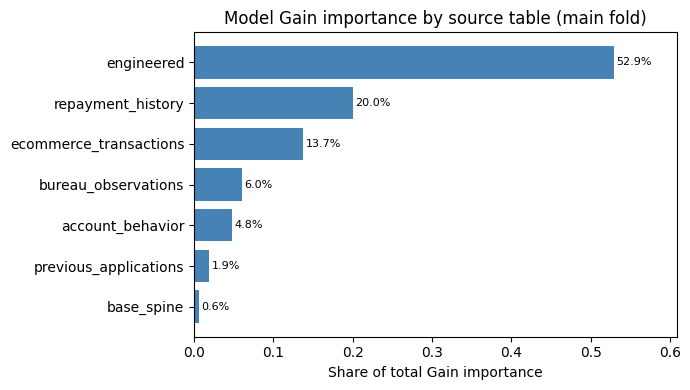

In [7]:
model, feats = fold_models[MAIN_FOLD]
va = train_df.iloc[folds[MAIN_FOLD][1]]

if hasattr(model, "booster_"):
    imp = pd.Series(model.booster_.feature_importance(importance_type="gain"), index=feats)
elif hasattr(model, "feature_importances_"):
    imp = pd.Series(model.feature_importances_, index=feats)
else:
    from sklearn.inspection import permutation_importance
    sample = va.sample(min(5000, len(va)), random_state=SEED)
    pi = permutation_importance(model, sample[feats], sample["target"], scoring="roc_auc", n_repeats=3, random_state=SEED)
    imp = pd.Series(pi.importances_mean, index=feats)
imp = (imp / imp.sum()).sort_values(ascending=False)

lb_path = os.path.join(OUT_DIR, "ks_leaderboard_aggregated.csv")
if os.path.exists(lb_path):
    source_map = pd.read_csv(lb_path).set_index("column_name")["source_table"].to_dict()
else:
    source_map = {}
source_map.update({c: "base_spine" for c in text_cols})
source_map.update({c: "engineered" for c in new_cols})

imp_table = pd.DataFrame({"importance": imp, "source_table": [source_map.get(c, "other") for c in imp.index]})
print("Top 25 features by model GAIN importance:")
print(imp_table.head(25).to_string())

by_source = imp_table.groupby("source_table")["importance"].sum().sort_values()
print("\nImportance share by source table (Gain-based):")
print(by_source.sort_values(ascending=False).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(by_source.index, by_source.values, color="steelblue")
for y_pos, val in enumerate(by_source.values):
    ax.text(val + 0.003, y_pos, f"{val:.1%}", va="center", fontsize=8)
ax.set_xlim(0, by_source.max() * 1.15)
ax.set_xlabel("Share of total Gain importance")
ax.set_title("Model Gain importance by source table (main fold)")
plt.tight_layout()
plt.show()

#### Cell 4.8 — Baseline Submission and Save Outputs

**What to do:** Select features on all 70,000 train rows, fit the baseline, predict test, validate the submission format and save `submission_baseline.csv` plus the feature list.

**Why:** Gives you a valid file early, and notebook 05 can compare every improvement against this baseline.

**What to look for:** 30,000 rows, each `application_id` once, all probabilities between 0 and 1, no NaN. The mean predicted probability should be near the train default rate (about 0.135).

In [8]:
from scipy.stats import rankdata

test_pred_prob = np.clip(test_preds_folds.mean(axis=0), 0.0, 1.0)

rank_folds = np.array([rankdata(p) / len(p) for p in test_preds_folds])
test_pred_rank = np.clip(rank_folds.mean(axis=0), 1e-6, 1.0 - 1e-6)

submission_prob = pd.DataFrame({"application_id": test_df["application_id"].values, "default_probability": test_pred_prob})
submission_rank = pd.DataFrame({"application_id": test_df["application_id"].values, "default_probability": test_pred_rank})

for sub in [submission_prob, submission_rank]:
    assert len(sub) == 30_000
    assert sub["application_id"].is_unique
    assert sub["default_probability"].between(0, 1).all()
    assert sub["default_probability"].notna().all()

submission_prob.to_csv(os.path.join(OUT_DIR, "submission_lgb_5fold_prob.csv"), index=False)
submission_rank.to_csv(os.path.join(OUT_DIR, "submission_lgb_5fold_rank.csv"), index=False)
pd.Series(selected_feats, name="feature").to_csv(os.path.join(OUT_DIR, "selected_features_v2.csv"), index=False)
full.to_parquet(os.path.join(OUT_DIR, "features_v2.parquet"), index=False)

print("Saved files to:", OUT_DIR)
print("1. submission_lgb_5fold_prob.csv (Mean Probability:", round(test_pred_prob.mean(), 4), ")")
print("2. submission_lgb_5fold_rank.csv (Rank-Averaged Probability)")
print("3. features_v2.parquet (Full shape:", full.shape, ")")

Saved files to: c:\Users\pevan\Documents\Rado\codingding\githubprojects\lending-money-probability\output
1. submission_lgb_5fold_prob.csv (Mean Probability: 0.1344 )
2. submission_lgb_5fold_rank.csv (Rank-Averaged Probability)
3. features_v2.parquet (Full shape: (100000, 565) )


## Next steps (notebook 05)

- Check train versus test drift per feature (the test period is Jul to Dec 2023) and drop features that drift strongly.
- Tune hyperparameters on the expanding-window folds above, then try a second model family (e.g., CatBoost / XGBoost) and blend by rank average.
- Compare against this baseline using the same `evaluate()` and the same folds.